# Vanilla LSTM Baseline — JalVaani
**Architecture:** 2-layer LSTM · hidden_dim=64 · lookback=30 days · district embedding (dim=8)  
**Static features:** Soil texture (9 values per district) repeated across all 30 time steps and concatenated with the time-series input at each step — mirrors how TFT injects static context  
**Purpose:** Deep learning baseline before attention mechanisms and spatial graph propagation are added  
**Split:** Train 2023-01-01 → 2024-09-30 · Val 2024-10-01 → 2025-01-31 · Test 2025-02-01 → 2025-04-22

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, clear_output
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size']  = 11

MASTER    = Path('../../Data Preprocessing/clean datasets/master_dataset.csv')
OUT_DIR   = Path('outputs')
OUT_DIR.mkdir(exist_ok=True)
(OUT_DIR / 'plots').mkdir(exist_ok=True)

# ── Hyper-parameters ──────────────────────────────────────────────────
LOOKBACK   = 30
HIDDEN_DIM = 64
NUM_LAYERS = 2
DROPOUT    = 0.2
EMBED_DIM  = 8
BATCH_SIZE = 128
LR         = 1e-3
MAX_EPOCHS = 100
PATIENCE   = 15
LR_PATIENCE= 5

TRAIN_END  = '2024-09-30'
VAL_END    = '2025-01-31'

TIME_SERIES_COLS = [
    'gwl_lag_7','gwl_lag_14','gwl_lag_30',
    'gwl_7d_change','gwl_30d_change',
    'rainfall_mm','rainfall_7d','rainfall_30d',
    'et_mm','soil_moisture','net_water_balance',
    'temp_max','temp_min','temp_mean','humidity_mean','vpd_approx',
    'month','day_of_year','is_monsoon',
]
STATIC_COLS = [
    'sand_0cm','clay_0cm','silt_0cm',
    'sand_10cm','clay_10cm','silt_10cm',
    'sand_30cm','clay_30cm','silt_30cm',
]
TARGET = 'gwl_mean'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device  : {device}')
print(f'PyTorch : {torch.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')

## 1. Load & Inspect Data

In [2]:
df = pd.read_csv(MASTER, parse_dates=['date'])
print(f'Rows      : {len(df):,}')
print(f'Districts : {df["district"].nunique()} → {sorted(df["district"].unique())}')
print(f'Date range: {df["date"].min().date()} → {df["date"].max().date()}')
print()

# Check which feature cols exist
ts_present     = [c for c in TIME_SERIES_COLS if c in df.columns]
static_present = [c for c in STATIC_COLS     if c in df.columns]
ts_missing     = [c for c in TIME_SERIES_COLS if c not in df.columns]
print(f'Time-series cols available : {len(ts_present)}/{len(TIME_SERIES_COLS)}')
print(f'Static cols available      : {len(static_present)}/{len(STATIC_COLS)}')
if ts_missing: print(f'Missing time-series cols   : {ts_missing}')

Rows      : 16,785
Districts : 24 → ['Akola', 'Amravati', 'Aurangabad', 'Beed', 'Bhandara', 'Chandrapur', 'Dhule', 'Gadchiroli', 'Gondia', 'Jalgaon', 'Kolhapur', 'Nagpur', 'Nanded', 'Nandurbar', 'Nashik', 'Pune', 'Raigad', 'Ratnagiri', 'Satara', 'Solapur', 'Thane', 'Wardha', 'Washim', 'Yavatmal']
Date range: 2023-03-02 → 2025-04-22

Time-series cols available : 19/19
Static cols available      : 9/9


In [3]:
# Missing data audit
audit_cols = ts_present + static_present + [TARGET]
missing_df = df[audit_cols].isnull().sum().to_frame('missing')
missing_df['pct'] = (missing_df['missing']/len(df)*100).round(2)
print('Missing values:')
display(missing_df[missing_df['missing']>0])

Missing values:


,missing,pct
gwl_lag_7,191,1.14
gwl_lag_14,374,2.23
gwl_lag_30,762,4.54
gwl_7d_change,191,1.14
gwl_30d_change,762,4.54
sand_0cm,2676,15.94
clay_0cm,2676,15.94
silt_0cm,2676,15.94
sand_10cm,2676,15.94
clay_10cm,2676,15.94


## 2. Normalise + Split

In [4]:
train_df = df[df['date'] <= TRAIN_END].copy()
val_df   = df[(df['date'] > TRAIN_END) & (df['date'] <= VAL_END)].copy()
test_df  = df[df['date'] > VAL_END].copy()

print(f'Train: {len(train_df):,}  ({train_df["date"].min().date()} → {train_df["date"].max().date()})')
print(f'Val  : {len(val_df):,}  ({val_df["date"].min().date()} → {val_df["date"].max().date()})')
print(f'Test : {len(test_df):,}  ({test_df["date"].min().date()} → {test_df["date"].max().date()})')

# Z-score normalisation — fit on train only
norm_cols = ts_present + [TARGET]
means = train_df[norm_cols].mean()
stds  = train_df[norm_cols].std().replace(0, 1)

for d in [train_df, val_df, test_df]:
    d[norm_cols] = (d[norm_cols] - means) / stds

# Normalise static cols (fill NaN with 0 after normalising)
static_means = train_df[static_present].mean()
static_stds  = train_df[static_present].std().replace(0, 1)
for d in [train_df, val_df, test_df]:
    d[static_present] = (d[static_present].fillna(static_means) - static_means) / static_stds

print(f'\nNormalisation stats fitted on train set.')
print(f'Target mean={means[TARGET]:.4f}  std={stds[TARGET]:.4f}')

Train: 11,964  (2023-03-02 → 2024-09-30)
Val  : 2,923  (2024-10-01 → 2025-01-31)
Test : 1,898  (2025-02-01 → 2025-04-22)

Normalisation stats fitted on train set.
Target mean=-14.3714  std=15.9713


## 3. Build Sliding-Window Dataset

In [5]:
class GWLDataset(Dataset):
    def __init__(self, windows):
        self.windows = windows
    def __len__(self):
        return len(self.windows)
    def __getitem__(self, idx):
        ts_seq, static, dist_id, target = self.windows[idx]
        return (
            torch.tensor(ts_seq,  dtype=torch.float32),
            torch.tensor(static,  dtype=torch.float32),
            torch.tensor(dist_id, dtype=torch.long),
            torch.tensor(target,  dtype=torch.float32),
        )

def build_windows(df, ts_cols, static_cols, target_col, lookback):
    windows = []
    for dist, grp in df.groupby('district'):
        grp   = grp.sort_values('date').reset_index(drop=True)
        ts    = grp[ts_cols].values
        stat  = grp[static_cols].values
        dids  = grp['district_id'].values
        tgts  = grp[target_col].values
        for i in range(lookback, len(grp)):
            ts_seq = ts[i-lookback:i]
            if np.isnan(ts_seq).any():
                continue
            sv = stat[i, :]
            sv = np.nan_to_num(sv, nan=0.0)
            if np.isnan(float(tgts[i])):
                continue
            windows.append((ts_seq, sv, int(dids[i]), float(tgts[i])))
    return windows

print('Building sliding windows ...')
train_windows = build_windows(train_df, ts_present, static_present, TARGET, LOOKBACK)
val_windows   = build_windows(val_df,   ts_present, static_present, TARGET, LOOKBACK)
test_windows  = build_windows(test_df,  ts_present, static_present, TARGET, LOOKBACK)

print(f'Windows — Train: {len(train_windows):,}  Val: {len(val_windows):,}  Test: {len(test_windows):,}')
ts_ex, st_ex, did_ex, tgt_ex = train_windows[0]
print(f'Sample window — ts_seq: {ts_ex.shape}  static: {st_ex.shape}  target: {tgt_ex:.4f}')

train_loader = DataLoader(GWLDataset(train_windows), batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(GWLDataset(val_windows),   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(GWLDataset(test_windows),  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

Building sliding windows ...
Windows — Train: 10,342  Val: 2,178  Test: 1,174
Sample window — ts_seq: (30, 19)  static: (9,)  target: 0.7322


## 4. Define LSTM Model

In [6]:
class VanillaLSTM(nn.Module):
    """
    Input per timestep:
        time-series features  [ts_input_dim]
      + soil texture (static) [static_dim]    ← same values repeated across all T steps
      + district embedding    [embed_dim]     ← same values repeated across all T steps
    → LSTM encoder → Linear head → predicted next-day GWL
    """
    def __init__(self, ts_input_dim, static_dim, n_districts, embed_dim, hidden_dim, num_layers, dropout):
        super().__init__()
        self.embed = nn.Embedding(n_districts, embed_dim)
        lstm_in    = ts_input_dim + static_dim + embed_dim
        self.lstm  = nn.LSTM(lstm_in, hidden_dim, num_layers, batch_first=True,
                             dropout=dropout if num_layers > 1 else 0.0)
        self.head  = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden_dim, 1))

    def forward(self, ts_seq, static_vec, dist_id):
        B, T, _ = ts_seq.shape
        emb     = self.embed(dist_id)                         # [B, embed_dim]
        stat    = static_vec.unsqueeze(1).expand(-1, T, -1)  # [B, T, static_dim]
        emb_exp = emb.unsqueeze(1).expand(-1, T, -1)         # [B, T, embed_dim]
        x       = torch.cat([ts_seq, stat, emb_exp], dim=-1) # [B, T, total_input]
        out, _  = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)           # [B]

n_districts = df['district_id'].nunique()
ts_dim      = len(ts_present)
static_dim  = len(static_present)
lstm_input  = ts_dim + static_dim + EMBED_DIM

model = VanillaLSTM(
    ts_input_dim=ts_dim, static_dim=static_dim,
    n_districts=n_districts, embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM, num_layers=NUM_LAYERS, dropout=DROPOUT
).to(device)

total_params = sum(p.numel() for p in model.parameters())
print(model)
print(f'\nTotal parameters : {total_params:,}')
print(f'LSTM input dim   : {lstm_input} = {ts_dim} ts + {static_dim} static + {EMBED_DIM} embed')

VanillaLSTM(
  (embed): Embedding(24, 8)
  (lstm): LSTM(36, 64, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=64, out_features=1, bias=True)
  )
)

Total parameters : 59,649
LSTM input dim   : 36 = 19 ts + 9 static + 8 embed


## 5. Train

In [8]:
optimizer  = torch.optim.Adam(model.parameters(), lr=LR)
scheduler  = ReduceLROnPlateau(optimizer, patience=LR_PATIENCE, factor=0.5)
criterion  = nn.MSELoss()

best_val_loss = float('inf')
patience_ctr  = 0
best_state    = None
train_losses  = []
val_losses    = []

print(f'Training LSTM — up to {MAX_EPOCHS} epochs | early stopping patience={PATIENCE}')
print(f'Device: {device}  |  Batch size: {BATCH_SIZE}  |  LR: {LR}')
print('-'*65)

epoch_bar = tqdm(range(1, MAX_EPOCHS+1), desc='Epochs')
for epoch in epoch_bar:
    # ── Train ──────────────────────────────────────────────────────────
    model.train()
    t_loss = 0.0
    for ts_seq, static_vec, dist_id, target in train_loader:
        ts_seq, static_vec, dist_id, target = (
            ts_seq.to(device), static_vec.to(device), dist_id.to(device), target.to(device)
        )
        optimizer.zero_grad()
        pred = model(ts_seq, static_vec, dist_id)
        loss = criterion(pred, target)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        t_loss += loss.item() * len(target)
    t_loss /= len(train_windows)

    # ── Val ────────────────────────────────────────────────────────────
    model.eval()
    v_loss = 0.0
    with torch.no_grad():
        for ts_seq, static_vec, dist_id, target in val_loader:
            ts_seq, static_vec, dist_id, target = (
                ts_seq.to(device), static_vec.to(device), dist_id.to(device), target.to(device)
            )
            v_loss += criterion(model(ts_seq, static_vec, dist_id), target).item() * len(target)
    v_loss /= len(val_windows)

    train_losses.append(t_loss)
    val_losses.append(v_loss)
    scheduler.step(v_loss)

    epoch_bar.set_postfix({'train_loss': f'{t_loss:.5f}', 'val_loss': f'{v_loss:.5f}',
                           'best_val': f'{best_val_loss:.5f}', 'patience': patience_ctr})

    if v_loss < best_val_loss:
        best_val_loss = v_loss
        best_state    = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        patience_ctr  = 0
    else:
        patience_ctr += 1
        if patience_ctr >= PATIENCE:
            print(f'\nEarly stop at epoch {epoch}  (best val_loss={best_val_loss:.5f})')
            break

print(f'Training complete. Best val loss: {best_val_loss:.5f}')
model.load_state_dict(best_state)
torch.save(best_state, OUT_DIR / 'lstm_checkpoint.pt')
print('Model saved → lstm_checkpoint.pt')

Training LSTM — up to 100 epochs | early stopping patience=15
Device: cpu  |  Batch size: 128  |  LR: 0.001
-----------------------------------------------------------------


Epochs:   0%|          | 0/100 [00:00<?, ?it/s]


Early stop at epoch 42  (best val_loss=0.00820)
Training complete. Best val loss: 0.00820
Model saved → lstm_checkpoint.pt


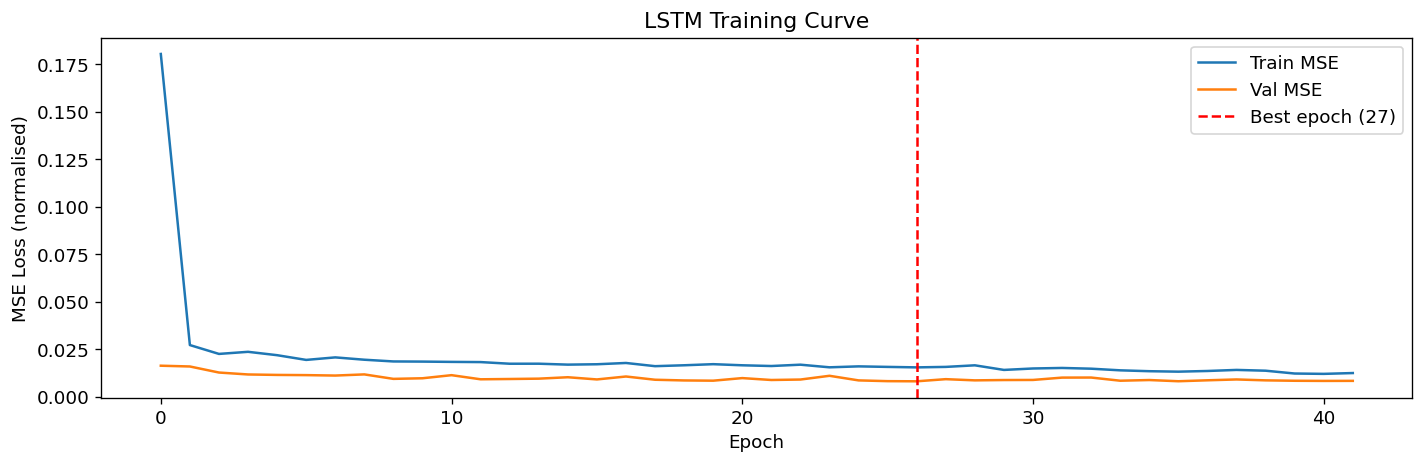

Ran 42 epochs  |  Best epoch: 27  |  Best val MSE: 0.00820


In [9]:
# Training curves
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train_losses, label='Train MSE', linewidth=1.5)
ax.plot(val_losses,   label='Val MSE',   linewidth=1.5)
best_ep = int(np.argmin(val_losses))
ax.axvline(best_ep, color='red', linestyle='--', label=f'Best epoch ({best_ep+1})')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss (normalised)')
ax.set_title('LSTM Training Curve')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'plots' / 'lstm_training_curve.png', dpi=150)
plt.show()
print(f'Ran {len(train_losses)} epochs  |  Best epoch: {best_ep+1}  |  Best val MSE: {best_val_loss:.5f}')

## 6. Evaluate

In [10]:
target_mean = float(means[TARGET])
target_std  = float(stds[TARGET])

def compute_metrics(actual, pred):
    a, p = np.array(actual, float), np.array(pred, float)
    rmse = np.sqrt(np.mean((a-p)**2))
    mae  = np.mean(np.abs(a-p))
    mask = a != 0
    mape = np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100
    return rmse, mae, mape

dist_map = dict(zip(df['district_id'], df['district']))

def run_eval(loader, windows, split):
    model.eval()
    records = []
    with torch.no_grad():
        for ts_seq, static_vec, dist_id, target in loader:
            ts_seq, static_vec, did = (
                ts_seq.to(device), static_vec.to(device), dist_id.to(device)
            )
            pred = model(ts_seq, static_vec, did).cpu().numpy()
            for i in range(len(target)):
                records.append({
                    'district_id': int(dist_id[i]),
                    'gwl_actual':  float(target[i]) * target_std + target_mean,
                    'gwl_pred':    float(pred[i])   * target_std + target_mean,
                    'split': split,
                })
    df_out = pd.DataFrame(records)
    df_out['district'] = df_out['district_id'].map(dist_map)
    r, m, mp = compute_metrics(df_out['gwl_actual'], df_out['gwl_pred'])
    print(f'  {split:<5}  RMSE={r:.4f}m  MAE={m:.4f}m  MAPE={mp:.2f}%')
    return df_out

print('Evaluation (denormalised, metres):')
val_results  = run_eval(val_loader,  val_windows,  'val')
test_results = run_eval(test_loader, test_windows, 'test')

Evaluation (denormalised, metres):
  val    RMSE=1.4465m  MAE=0.7060m  MAPE=18.09%
  test   RMSE=2.7346m  MAE=1.0636m  MAPE=8.91%


In [11]:
# Per-district test RMSE
dist_metrics = []
for did, grp in test_results.groupby('district_id'):
    r, m, mp = compute_metrics(grp['gwl_actual'].values, grp['gwl_pred'].values)
    dist_metrics.append({'district': dist_map.get(did, did), 'rmse': round(r,4), 'mae': round(m,4)})
dm = pd.DataFrame(dist_metrics).sort_values('rmse', ascending=False)
print('Per-district test RMSE:')
display(dm.style.background_gradient(subset=['rmse'], cmap='YlOrRd'))

Per-district test RMSE:


,district,rmse,mae
6,Dhule,10.899600,6.675400
9,Jalgaon,5.840800,4.406300
14,Nashik,2.321300,1.558000
7,Gadchiroli,1.559300,0.962500
18,Satara,1.444600,1.444600
10,Kolhapur,1.274200,0.849100
19,Solapur,1.189600,0.644200
13,Nandurbar,1.154700,0.843800
0,Akola,1.013200,0.846700
2,Aurangabad,0.977700,0.878200


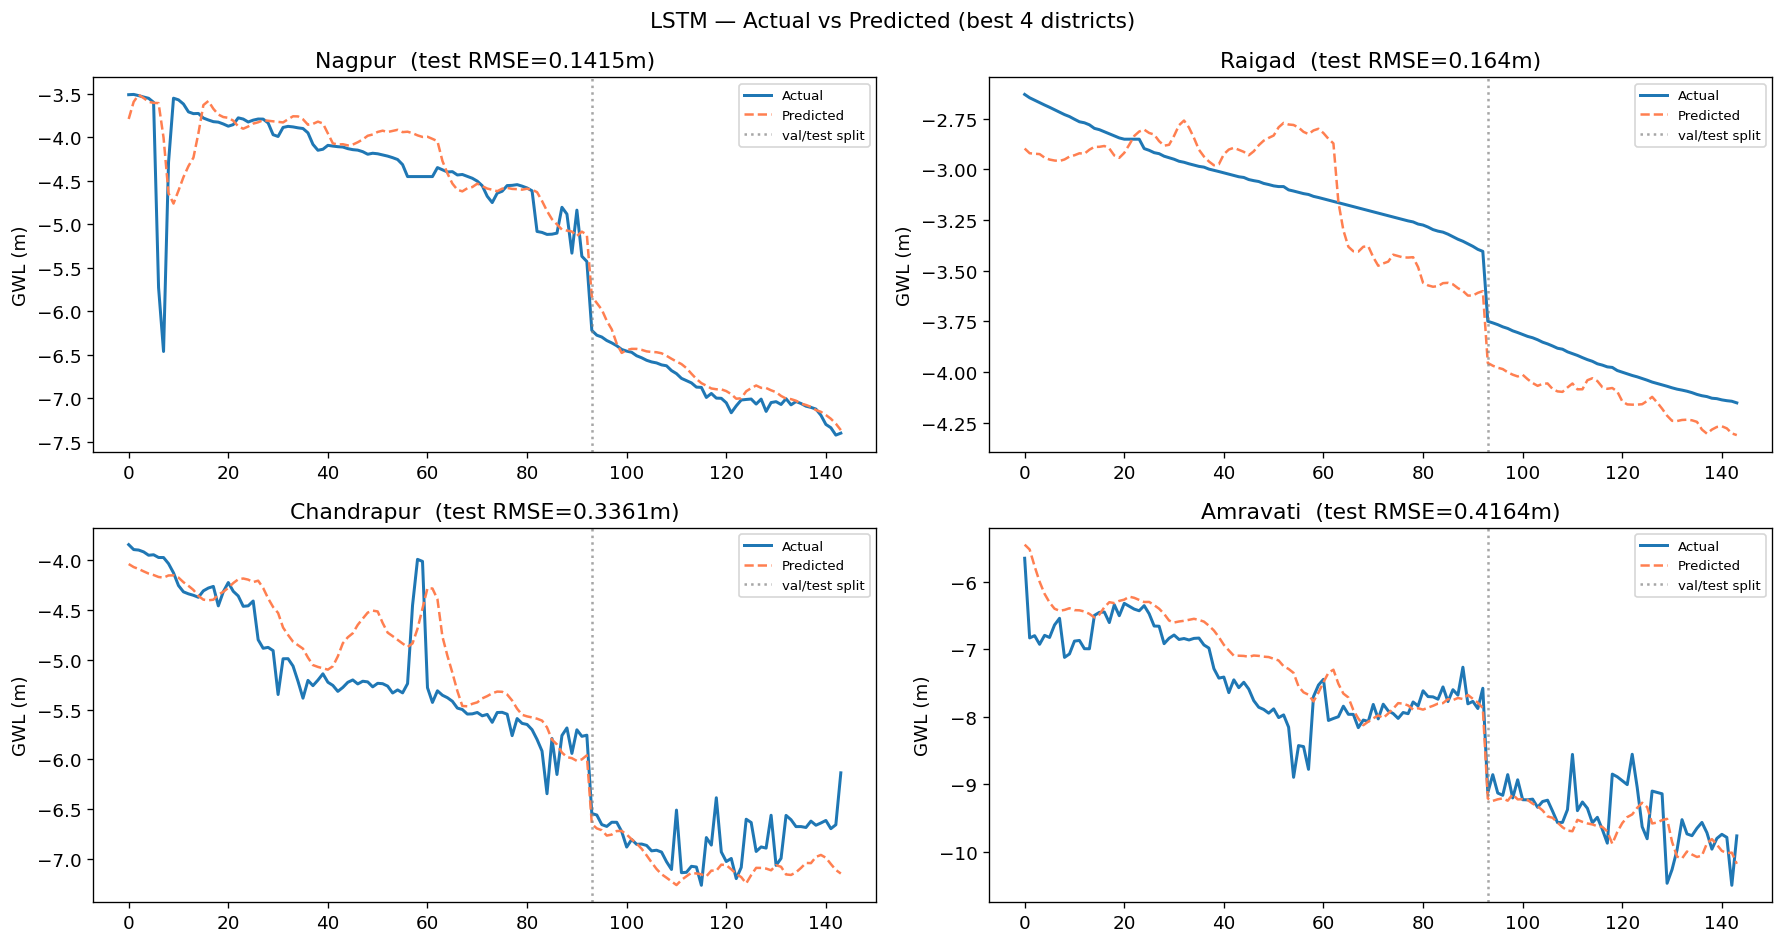

In [12]:
# Actual vs predicted plots for 4 best districts
all_results = pd.concat([val_results, test_results], ignore_index=True)
best_dists  = dm.nsmallest(4, 'rmse')['district'].tolist()

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes = axes.flatten()
for i, dist in enumerate(best_dists):
    sub = all_results[all_results['district']==dist].reset_index(drop=True)
    axes[i].plot(sub.index, sub['gwl_actual'], label='Actual',    linewidth=1.8)
    axes[i].plot(sub.index, sub['gwl_pred'],   label='Predicted', linewidth=1.5, linestyle='--', color='coral')
    val_end_idx = (sub['split']=='val').sum()
    axes[i].axvline(val_end_idx, color='gray', linestyle=':', alpha=0.7, label='val/test split')
    rmse_val = dm[dm['district']==dist]['rmse'].values[0]
    axes[i].set_title(f'{dist}  (test RMSE={rmse_val}m)')
    axes[i].set_ylabel('GWL (m)')
    axes[i].legend(fontsize=8)
plt.suptitle('LSTM — Actual vs Predicted (best 4 districts)', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / 'plots' / 'lstm_actual_vs_pred.png', dpi=150)
plt.show()

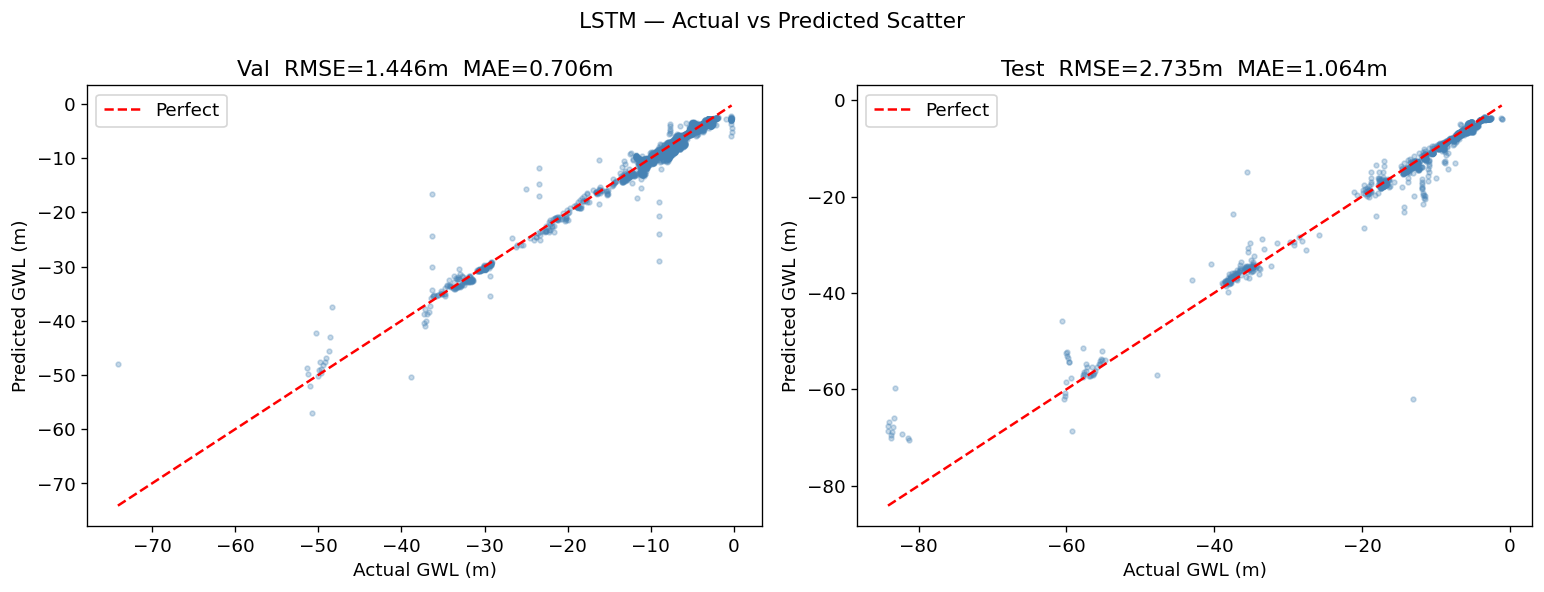

In [13]:
# Scatter — actual vs predicted
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, split, results in [
    (axes[0], 'Val',  val_results),
    (axes[1], 'Test', test_results),
]:
    a, p = results['gwl_actual'].values, results['gwl_pred'].values
    ax.scatter(a, p, alpha=0.3, s=8, color='steelblue')
    mn, mx = min(a.min(), p.min()), max(a.max(), p.max())
    ax.plot([mn,mx],[mn,mx],'r--', linewidth=1.5, label='Perfect')
    r, m, _ = compute_metrics(a, p)
    ax.set_title(f'{split}  RMSE={r:.3f}m  MAE={m:.3f}m')
    ax.set_xlabel('Actual GWL (m)')
    ax.set_ylabel('Predicted GWL (m)')
    ax.legend()
plt.suptitle('LSTM — Actual vs Predicted Scatter', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / 'plots' / 'lstm_scatter.png', dpi=150)
plt.show()

## 7. Save Outputs

In [14]:
preds_df = pd.concat([val_results, test_results], ignore_index=True)
preds_df = preds_df[['district','district_id','split','gwl_actual','gwl_pred']]
preds_df.rename(columns={'gwl_pred':'gwl_predicted'}, inplace=True)
preds_df.to_csv(OUT_DIR / 'lstm_predictions.csv', index=False)
dm.to_csv(OUT_DIR / 'lstm_metrics.csv', index=False)

print('Saved: lstm_predictions.csv')
print('Saved: lstm_metrics.csv')
print('Saved: lstm_checkpoint.pt')
print('Saved: lstm_training_curve.png')
print('Saved: lstm_actual_vs_pred.png')
print('Saved: lstm_scatter.png')

t_r, t_m, t_mp = compute_metrics(test_results['gwl_actual'], test_results['gwl_pred'])
print(f'\nFinal test RMSE : {t_r:.4f} m')
print(f'Final test MAE  : {t_m:.4f} m')
print(f'Final test MAPE : {t_mp:.2f} %')

Saved: lstm_predictions.csv
Saved: lstm_metrics.csv
Saved: lstm_checkpoint.pt
Saved: lstm_training_curve.png
Saved: lstm_actual_vs_pred.png
Saved: lstm_scatter.png

Final test RMSE : 2.7346 m
Final test MAE  : 1.0636 m
Final test MAPE : 8.91 %
